# Layer 3: two moods that can switch within a session

Layer 2 gave each session one hidden mood for all its tracks: *Engaged* (few skips) or *Browsing* (many skips). It explained most of the differences between sessions, but its predictive checks showed two things it could not reproduce:

- the **within-session gap**: in the real data a skip is followed by another skip more often than the session's own skip rate explains (0.10 in the real data, 0 in Layer 2),
- the **skip/play changes**: real sessions change from skip to play less often than Layer 2 predicts (2.74 against 3.95 per session). Skips come in runs.

In this notebook the mood can **switch** from one track to the next. Each track has its own hidden mood, and the mood of a track only depends on the mood of the track before: this is a hidden Markov model. If the switch probabilities are 0, we are back to Layer 2.

(the goal is to see whether adding switching beats Layer 2)

In [1]:
import json
import os
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mood_switching as ms
import posterior as po
import session_types as st
from checks import (all_checks, average_log_score, load_sessions,
                    real_data_checks, split_users, to_matrix)

SEED = 2026
rng = np.random.default_rng(SEED)

N_DRAWS = 20_000     # importance sampling draws
DF = 4               # degrees of freedom of the Student-t proposal
N_POSTERIOR = 1000   # resampled posterior draws (predictive checks, test score)
N_STARTS = 10        # EM starting points

# Beta(2, 2) for theta_e, theta_b, p0, q_eb and q_be
# EM uses Beta(3, 3) to find the mode on the log-odds scale
PRIOR = ms.PRIOR
EM_PRIOR = po.log_odds_prior(PRIOR)

#make the dirs for the results
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

BLUE = "#00a10d"
ORANGE = "#aa3102"
GREY = "#a4a4a4"

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GREY,
    "xtick.color": GREY,
    "ytick.color": GREY,
    "axes.labelcolor": GREY,
})

The model functions are in `mood_switching.py` and the general tools (importance sampling, Hessian, predictive checks) in `posterior.py`, used as they are in Layer 2.
We also import `session_types.py` (Layer 2) to compare the two models.

## 1. The data

We use the same sessions and the same training/test split as Layers 1 and 2 (split by user, seed 2026): 20% of the users are kept aside, only for the additional analysis at the end.

The results of Layers 1 and 2 are read from `results/layer1.json` and `results/layer2.json` for the comparisons.

In [2]:
sessions = load_sessions()
train, test = split_users(sessions, seed=SEED)
train_skips, train_mask = to_matrix(train)
test_skips, test_mask = to_matrix(test)
train_lengths = train_mask.sum(axis=1)

with open("results/layer1.json") as file:
    layer1 = json.load(file)
with open("results/layer2.json") as file:
    layer2 = json.load(file)

print(f"Training: {len(train_skips)} sessions, {train_mask.sum()} tracks, skip rate {train['skip'].mean():.4f}")
print(f"Test: {len(test_skips)} sessions, {test_mask.sum()} tracks")
print(f"Session length: {train_lengths.min()} to {train_lengths.max()} tracks, mean {train_lengths.mean():.2f}")

Training: 4314 sessions, 67122 tracks, skip rate 0.4185
Test: 1061 sessions, 16595 tracks
Session length: 10 to 20 tracks, mean 15.56


We recall the two statistics that Layer 2 could not reproduce, read from `results/layer2.json`:

In [3]:
layer2_checks = pd.DataFrame(layer2["predictive_checks"]).T
layer2_checks.loc[["within-session gap", "skip/play changes"],
                  ["real data", "simulated mean", "share at least as large"]].round(4)

,real data,simulated mean,share at least as large
within-session gap,0.1013,-0.0001,0.0
skip/play changes,2.7415,3.9486,1.0


The training data have 4314 sessions and 67 122 tracks, the same as in Layers 1 and 2 (skip rate around 0.42).
The test data is only used at the end for extra investigation.

The table shows what Layer 3 must fix: Layer 2 gives a within-session gap of 0 (real data 0.10) and too many skip/play changes (3.95 against 2.74).

## 2. The model

For session $i$ with $n_i$ tracks, $y_{it} = 1$ if track $t$ is skipped and $0$ if it is played.

- $z_{it} \in \{E, B\}$ is the hidden mood of track $t$ of session $i$ (Engaged or Browsing). It can now change from one track to the next.
- $p_0 = P(z_{i1} = E)$ is the probability that a session starts Engaged.
- $q_{EB} = P(z_{it} = B \mid z_{i,t-1} = E)$ is the probability to switch from Engaged to Browsing between two tracks, and $q_{BE}$ the probability to switch back.
- $\theta_E$ and $\theta_B$ are the skip rates of the two moods.

**The model**

$$z_{i1} \sim \text{Bernoulli}(p_0), \qquad P(z_{it} = j \mid z_{i,t-1} = k) = A_{kj}, \qquad y_{it} \mid z_{it} \sim \text{Bernoulli}(\theta_{z_{it}})$$

with the transition matrix (rows: mood before, columns: mood after)

$$A = \begin{pmatrix} 1 - q_{EB} & q_{EB} \\ q_{BE} & 1 - q_{BE} \end{pmatrix}$$

The moods form a Markov chain: the mood of a track only depends on the mood of the track before. Given its mood, a track is skipped independently of the others. This is a hidden Markov model.

**Likelihood.** We do not know the moods, so we add all the possible sequences of moods (law of total probability). There are $2^{n_i}$ of them, so we do not write them one by one: the **forward algorithm** adds them one track at a time. With $\alpha_t(j) = P(y_{i1}, \dots, y_{it}, z_{it} = j)$:

$$\alpha_1(j) = P(z_{i1} = j)\, P(y_{i1} \mid j), \qquad \alpha_t(j) = \Big(\sum_k \alpha_{t-1}(k)\, A_{kj}\Big)\, P(y_{it} \mid j), \qquad p(y_i) = \alpha_{n_i}(E) + \alpha_{n_i}(B)$$

These numbers become tiny after many tracks, so the code divides the two $\alpha_t$ by their sum after each track (this is called scaling). The sum is $c_t = P(y_{it} \mid y_{i1}, \dots, y_{i,t-1})$, and $\log p(y_i) = \sum_t \log c_t$. This gives exactly the same numbers as working in logs, but much faster.

**The order of the tracks now matters**: in Layer 2 only $n_i$ and $s_i$ appeared. Here, two skips in a row are more likely than two skips far apart, because the mood tends to stay the same.

**Link with Layer 2**: if $q_{EB} = q_{BE} = 0$, nobody switches, the mood of the first track is the mood of the whole session, and we are back to Layer 2.

**Priors.**

| Parameter | Prior |  |
|---|---|---|
| $\theta_E, \theta_B$ | Beta(2, 2), with $\theta_E < \theta_B$ | Same as Layer 2. The order fixes the labels: "engaged" always means the mood with fewer skips |
| $p_0$ | Beta(2, 2) | Same as Layer 2 |
| $q_{EB}, q_{BE}$ | Beta(2, 2) | We have no strong knowledge about how often listeners switch |

Beta(2, 2) has the weight of 4 observations, while the data have about 63,000 pairs of neighbouring tracks, so the prior should matter very little (we will check it later).

As an example, we take $\theta_E = 0.1$, $\theta_B = 0.7$, $p_0 = 0.5$ and $q_{EB} = q_{BE} = 0.2$, and a session of two skips. By hand, we add the four sequences of moods:

| moods | P(moods) | P(two skips \| moods) | product |
|---|---|---|---|
| E, E | 0.5 × 0.8 = 0.4 | 0.1 × 0.1 = 0.01 | 0.004 |
| E, B | 0.5 × 0.2 = 0.1 | 0.1 × 0.7 = 0.07 | 0.007 |
| B, E | 0.5 × 0.2 = 0.1 | 0.7 × 0.1 = 0.07 | 0.007 |
| B, B | 0.5 × 0.8 = 0.4 | 0.7 × 0.7 = 0.49 | 0.196 |

So $p(y) = 0.214$, and $P(\text{Browsing at track 2} \mid \text{two skips}) = (0.007 + 0.196)/0.214 = 0.949$.

In [4]:
example = {"theta_e": 0.1, "theta_b": 0.7, "p0": 0.5, "q_eb": 0.2, "q_be": 0.2}
two_skips = np.array([[1, 1]])
two_tracks = np.ones((1, 2), dtype=bool)

likelihood = np.exp(ms.log_likelihood(example, two_skips, two_tracks))
gamma, _ = ms.state_probabilities(example, two_skips, two_tracks)
p_browsing = gamma[0, 1, 1]   # session 0, track 2, Browsing
print(f"Likelihood of two skips: {likelihood:.4f} (by hand 0.214)")
print(f"P(Browsing at track 2 | two skips): {p_browsing:.4f} (by hand 0.949)")

Likelihood of two skips: 0.2140 (by hand 0.214)
P(Browsing at track 2 | two skips): 0.9486 (by hand 0.949)


Both numbers agree with the hand computation. With the same skip rates, Layer 2 gave 0.25 and 0.98: here the mood can switch, so two skips say a little less about the mood of each track.

We now check that the order of the tracks matters. The two sessions below both have 2 skips out of 4 tracks, but in the first one the skips are next to each other:

In [5]:
same_counts = np.array([[1, 1, 0, 0],
                        [1, 0, 1, 0]])
four_tracks = np.ones((1, 4), dtype=bool)
pd.DataFrame({
    "Layer 2": [np.exp(st.log_likelihood(example, row[None], four_tracks)) for row in same_counts],
    "Layer 3": [np.exp(ms.log_likelihood(example, row[None], four_tracks)) for row in same_counts],
}, index=["skip, skip, play, play", "skip, play, skip, play"]).round(4)

,Layer 2,Layer 3
"skip, skip, play, play",0.0261,0.0554
"skip, play, skip, play",0.0261,0.0338


Layer 2 gives the same probability to both sessions (only the number of skips counts). Layer 3 finds the first session about 1.6 times more likely, because the skips form a run, which is what the real data showed.

We now want to check that log_likelihood computes the right number, by computing it by brute force and comparing them, as in Layer 2.

We write every possible session of 1 to 4 tracks (30 sessions) in rows of 6 cells, with junk 1s after the end of each session to check that the mask really hides them. For each session we go through **every sequence of moods** ($2^{n_i}$ of them), multiply the probabilities directly (without logs and without the forward algorithm), and add them up.

Then, we check that it agrees with the code, which uses the forward algorithm in logs.

In [6]:
from itertools import product

# Every session of 1 to 4 tracks:
blocks = []
tiny_lengths = []
for length in range(1, 5):
    codes = np.arange(2 ** length)
    digits = (codes[:, None] >> np.arange(6)) & 1
    # junk 1s after the end of the session
    blocks.append(np.where(np.arange(6) < length, digits, 1))
    tiny_lengths.append(np.full(2 ** length, length))
tiny_skips = np.vstack(blocks)
tiny_lengths = np.concatenate(tiny_lengths)
tiny_mask = np.arange(6) < tiny_lengths[:, None]

q = {"theta_e": 0.23, "theta_b": 0.81, "p0": 0.37, "q_eb": 0.12, "q_be": 0.31}
theta = {"E": q["theta_e"], "B": q["theta_b"]}
start = {"E": q["p0"], "B": 1 - q["p0"]}
switch = {("E", "E"): 1 - q["q_eb"], ("E", "B"): q["q_eb"],
          ("B", "E"): q["q_be"], ("B", "B"): 1 - q["q_be"]}

def brute_force(y):
    '''Add P(moods) * P(y | moods) over every sequence of moods'''
    total = 0
    for moods in product("EB", repeat=len(y)):
        p = start[moods[0]]
        for before, after in zip(moods[:-1], moods[1:]):
            p *= switch[(before, after)]
        for mood, skip in zip(moods, y):
            p *= theta[mood] if skip == 1 else 1 - theta[mood]
        total += p
    return total

direct = np.array([brute_force(row[:length]) for row, length in zip(tiny_skips, tiny_lengths)])
ours = np.array([np.exp(ms.log_likelihood(q, tiny_skips[[i]], tiny_mask[[i]]))
                 for i in range(len(tiny_skips))])
print(f"{len(direct)} sessions, largest difference: {np.abs(ours - direct).max():.1e}")
print(f"Sum over the 16 sessions of 4 tracks: {direct[tiny_lengths == 4].sum():.6f}")

30 sessions, largest difference: 1.1e-16
Sum over the 16 sessions of 4 tracks: 1.000000


The brute force agrees with the forward algorithm to a rounding error ($10^{-16}$), and the probabilities of all sessions of 4 tracks add up to 1.

We can therefore conclude that the model is a proper probability distribution, that the forward algorithm is right and that the mask works.

Last check: with $q_{EB} = q_{BE} = 0$, Layer 3 should give exactly the Layer 2 log-likelihood. We compare the two on the real training data, with the Layer 2 values of the skip rates and of $p_0$:

In [7]:
no_switch = {**layer2["em_mode"], "q_eb": 0.0, "q_be": 0.0}
layer2_value = st.log_likelihood(layer2["em_mode"], train_skips, train_mask)
layer3_value = ms.log_likelihood(no_switch, train_skips, train_mask)
print(f"Layer 2: {layer2_value:.6f}")
print(f"Layer 3 without switching: {layer3_value:.6f}")
print(f"Difference: {abs(layer3_value - layer2_value):.1e}")

Layer 2: -32292.236137
Layer 3 without switching: -32292.236137
Difference: 3.6e-12


The two log-likelihoods are equal (up to rounding). So Layer 2 is exactly the special case of Layer 3 with no switching, and any improvement in Layer 3 can only come from the switches.

## 3. Validation on simulated data

Before touching the real data, we fit the model on simulated data, as in Layer 2.

We simulate as many sessions as in the training data, **with the same lengths**.

Our true values are: $\theta_E = 0.08$, $\theta_B = 0.80$, $p_0 = 0.55$, $q_{EB} = 0.05$, $q_{BE} = 0.06$.

- In the long run, the share of Engaged tracks is $q_{BE}/(q_{EB} + q_{BE}) = 0.06/0.11 = 0.55$, the same as $p_0$, so the share of each mood stays about the same along a session.
- The overall skip rate is then about $0.55 \times 0.08 + 0.45 \times 0.80 = 0.40$, close to Yambda's 0.42.
- A mood lasts on average $1/q_{EB} = 20$ tracks (Engaged) and $1/q_{BE} \approx 17$ tracks (Browsing), so a session of 15 tracks has on average about $14.6 \times 0.055 \approx 0.8$ switches: many sessions have none, some have one or two.

We build our simulator with discrete inverse transform through uniforms, as in Layer 2. A number below $p_0$ makes the first track Engaged. Then, at each track, a number below the probability to be Engaged (given the mood before) gives the new mood, and a number below the track's skip rate makes it skipped. We first check it on a large sample of 50 times the training sessions.

In [8]:
TRUE = {"theta_e": 0.08, "theta_b": 0.80, "p0": 0.55, "q_eb": 0.05, "q_be": 0.06}
sim_skips, sim_mask, sim_engaged = ms.simulate(TRUE, train_lengths, rng)

big_skips, big_mask, big_engaged = ms.simulate(TRUE, np.repeat(train_lengths, 50),
                                               np.random.default_rng(SEED))
again = ms.simulate(TRUE, np.repeat(train_lengths, 50), np.random.default_rng(SEED))
print("Same seed, same output:", np.array_equal(again[0], big_skips))
print("Same lengths as the training data:", np.array_equal(sim_mask, train_mask))

# Pairs of neighbouring tracks: mood before and mood after, where both tracks exist
pairs = big_mask[:, 1:]
before, after = big_engaged[:, :-1][pairs], big_engaged[:, 1:][pairs]

pd.DataFrame({
    "true": [0.55, 0.08, 0.80, 0.05, 0.06, 0.40],
    "simulated": [big_engaged[:, 0].mean(),
                  big_skips[big_engaged & big_mask].mean(),
                  big_skips[~big_engaged & big_mask].mean(),
                  (~after[before]).mean(),     # Engaged then Browsing
                  after[~before].mean(),       # Browsing then Engaged
                  big_skips[big_mask].mean()],
}, index=["first track Engaged (p0)", "skip rate, Engaged", "skip rate, Browsing",
          "switch Engaged to Browsing", "switch Browsing to Engaged",
          "overall skip rate"]).round(4)

Same seed, same output: True
Same lengths as the training data: True


,true,simulated
first track Engaged (p0),0.55,0.5526
"skip rate, Engaged",0.08,0.0801
"skip rate, Browsing",0.80,0.7998
switch Engaged to Browsing,0.05,0.0497
switch Browsing to Engaged,0.06,0.0601
overall skip rate,0.40,0.4039


Our simulator finds the true values to the 2nd or 3rd decimal.

### 3.1 Finding the mode with EM
EM alternates the same two steps as in Layer 2, but now on tracks instead of sessions (this version of EM for hidden Markov models is called Baum-Welch):

- E-step: for each track, the probability $\gamma_{it}(E)$ that it is Engaged, and for each pair of neighbouring tracks, the probability $\xi_{it}(k, j)$ of mood $k$ then mood $j$. Both come from Bayes' rule, computed with the forward algorithm (section 2) and the same idea run backwards (backward algorithm): $\gamma_{it}(j) = \alpha_t(j)\,\beta_t(j)/p(y_i)$, where $\beta_t(j) = P(y_{i,t+1}, \dots, y_{in_i} \mid z_{it} = j)$.
- M-step: the same Beta mode as in Layer 2, with expected counts:
  - $\theta_E$: expected skips in Engaged tracks over expected Engaged tracks, $\theta_E = (\sum_{i,t} \gamma_{it}(E)\, y_{it} + \alpha - 1)/(\sum_{i,t} \gamma_{it}(E) + \alpha + \beta - 2)$,
  - $p_0$: expected Engaged first tracks over the number of sessions,
  - $q_{EB}$: expected switches from Engaged to Browsing over expected Engaged tracks that have a next track, and the same for $q_{BE}$.

As in Layer 2, EM uses the prior Beta(3, 3), so it finds the peak of the posterior on the log-odds scale (where importance sampling works).

We start EM from 10 random points drawn from the prior. Unlike Layer 2, we do not run a fixed number of iterations: EM stops when one more step improves the log-posterior by less than $10^{-8}$ (at most 2000 steps). When the two moods are hard to tell apart, EM can climb very slowly, and a fixed number of steps could stop before the peak. The last column gives the number of steps each start needed.

We check that the log-posterior never decreases and whether every start ends at the same point. This is more important than in Layer 2: EM for hidden Markov models can get stuck at a local peak or in a very flat region, so different starts could end at different points.

In [9]:
sim_starts = [ms.random_start(rng) for _ in range(N_STARTS)]
sim_em, sim_mode, sim_histories = po.em_from_starts(ms.em, sim_starts, sim_skips, sim_mask, EM_PRIOR)
sim_em["iterations"] = [len(history) - 1 for history in sim_histories]
sim_em.round({**{name: 6 for name in ms.NAMES}, "log-posterior": 4})

,theta_e,theta_b,p0,q_eb,q_be,log-posterior,largest decrease,iterations
0,0.081646,0.801514,0.534807,0.050720,0.063360,-35428.0538,0.0,42
1,0.081646,0.801514,0.534807,0.050720,0.063360,-35428.0538,0.0,41
2,0.081646,0.801514,0.534807,0.050720,0.063360,-35428.0538,0.0,35
3,0.081646,0.801514,0.534807,0.050720,0.063360,-35428.0538,0.0,47
4,0.406436,0.410962,0.414327,0.411424,0.713617,-45383.5609,0.0,2000
5,0.081646,0.801514,0.534807,0.050720,0.063360,-35428.0538,0.0,81
6,0.081646,0.801514,0.534807,0.050720,0.063360,-35428.0538,0.0,41
7,0.081646,0.801514,0.534807,0.050720,0.063360,-35428.0538,0.0,66
8,0.081646,0.801514,0.534807,0.050720,0.063360,-35428.0538,0.0,47
9,0.406448,0.410626,0.466628,0.432004,0.650957,-45383.3037,0.0,2000


8 of the 10 starts reach the same point in 35 to 81 steps, and the log-posterior never decreases (the largest decrease is 0).

The 2 other starts get stuck in a very flat region where $\theta_E \approx \theta_B \approx 0.41$: the two moods look the same, so EM has almost no reason to separate them and moves very slowly (the bad start described in Layer 2). They never meet the stopping rule (2000 steps), and their log-posterior is much lower (−45,384 against −35,428), so `em_from_starts` keeps the best start. This is why we use several starts.

### 3.2 Importance sampling for the posterior
We build the whole posterior exactly as in Layer 2, with the same functions of `posterior.py`:

- Proposal: a Student-t with 4 degrees of freedom on the log-odds scale, centred at the EM mode, with scale matrix $(-H)^{-1}$, where $H$ is the Hessian of the log-posterior at the mode (central differences). It is now a 5 × 5 matrix.
- Weights $w = \text{posterior}/q$, in logs, normalized with log-sum-exp.
- Draws with $\theta_E \ge \theta_B$ get weight 0.

Each draw needs one forward pass over all sessions, so this step takes about 20 seconds.

In [10]:
sim_log_post = partial(ms.log_posterior, skips=sim_skips, mask=sim_mask, prior=PRIOR)
sim_fit = po.importance_sampling_at_mode(sim_log_post, po.to_vector(sim_mode, ms.NAMES),
                                         N_DRAWS, rng, DF)
po.posterior_table(sim_fit, ms.NAMES, truth=TRUE).round(5)

,mean,sd,low,median,high,true value,inside 95%
theta_e,0.08164,0.00206,0.07770,0.08162,0.08573,0.08,True
theta_b,0.80150,0.00317,0.79518,0.80153,0.80771,0.80,True
p0,0.53487,0.00914,0.51699,0.53490,0.55280,0.55,True
q_eb,0.05072,0.00166,0.04749,0.05070,0.05404,0.05,True
q_be,0.06335,0.00200,0.05952,0.06331,0.06731,0.06,True


All five true values fall within the 95% intervals. The intervals of $q_{EB}$ and $q_{BE}$ are wider (in relative terms) than those of the skip rates: a switch is seen only a few times per session, while every track says something about the skip rates.

### 3.3 Diagnostics of the proposal

We check the same three elements as in Layer 2:
- the number of draws that break θ_E < θ_B (weight 0) (should be low),
- the effective sample size $\text{ESS} = 1/\sum_k \bar w_k^2$ (should be close to the value of a Student-t(4) proposal on a Normal target),
- the largest weight (should be tiny).

In [11]:
po.proposal_diagnostics(sim_fit).round(6)

draws outside the support (weight 0)        0.000000
draws                                   20000.000000
ESS                                     15997.472668
ESS share                                   0.799874
largest weight                              0.000082
dtype: float64

The benchmark of Layer 2 (0.866) was computed in 3 dimensions. The ESS of a Student-t proposal depends on the number of dimensions, so we compute it again in **5 dimensions**, with the same functions as in Layer 2:

In [12]:
# Own generator, so the random draws in the rest of the notebook do not change
check_rng = np.random.default_rng(SEED + 1)
zero, identity = np.zeros(len(ms.NAMES)), np.eye(len(ms.NAMES))
normal_target = partial(po.normal_log_density, center=zero, cov=identity)
t_draws = po.student_t_draws(zero, identity, DF, 100_000, check_rng)
t_check = po.importance_sampling(normal_target, t_draws,
                                 po.student_t_log_density(t_draws, zero, identity, DF))
print(f"ESS share, Student-t(4) proposal for a 5-dimensional Normal target: {t_check['ess_share']:.3f}")

ESS share, Student-t(4) proposal for a 5-dimensional Normal target: 0.799


In 5 dimensions the benchmark is 0.80 instead of 0.866: the heavy tails of the Student-t cost more when there are more dimensions. Our ESS share is exactly this value, so the proposal, and so the mode and the Hessian it is built from, fits the posterior. No draw breaks θ_E < θ_B, and the largest weight is tiny.

## 4. Choice of the proposal

As in Layer 2, we compare three proposals on the simulated data set of section 3, with the same number of draws:

- the Student-t (4 df) at the mode (which we have done above),
- the prior itself: Beta(2, 2) draws for each parameter, moved to the log-odds scale,
- a Normal at the mode with half the standard deviation: its tails are lighter than the target's, so it might worsen the weights.

We evaluate and compare our proposals in the same way as in section 3:

In [13]:
center = sim_fit["center"]
narrow_cov = sim_fit["shape"] / 4   # half the standard deviation
prior_draws = po.prior_draws_log_odds(PRIOR, ms.NAMES, N_DRAWS, rng)
narrow_draws = po.normal_draws(center, narrow_cov, N_DRAWS, rng)
proposals = {
    "Student-t (4 df) at the mode": (
        sim_fit["draws"], po.student_t_log_density(sim_fit["draws"], center, sim_fit["shape"], DF)),
    "prior Beta(2, 2)": (
        prior_draws, po.log_beta_prior_log_odds(prior_draws, PRIOR, ms.NAMES)),
    "Normal at the mode, half the sd": (
        narrow_draws, po.normal_log_density(narrow_draws, center, narrow_cov)),
}

comparison = []
for name, (draws, log_proposal) in proposals.items():
    result = po.importance_sampling(sim_log_post, draws, log_proposal)
    q_eb = po.to_params(draws, ms.NAMES)["q_eb"]
    comparison.append({
        "proposal": name,
        "draws with theta_e < theta_b": result["n_valid"],
        "ESS": round(result["ess"], 1),
        "ESS share": round(result["ess_share"], 5),
        "largest weight": round(result["largest_weight"], 4),
        "q_eb mean": (f"{(result['weights'] * q_eb).sum():.4f}"
                      if result["n_valid"] > 0 else "no valid draw"),
    })
comparison = pd.DataFrame(comparison)
comparison

,proposal,draws with theta_e < theta_b,ESS,ESS share,largest weight,q_eb mean
0,Student-t (4 df) at the mode,20000,15997.5,0.79987,0.0001,0.0507
1,"prior Beta(2, 2)",9932,1.0,0.00005,1.0000,0.1733
2,"Normal at the mode, half the sd",20000,301.3,0.01506,0.0333,0.0507


We observe:

- The Student-t at the mode keeps about 80% of its draws useful, the 5-dimensional benchmark of section 3.3.
- The prior spreads its draws over the whole space, while the posterior only stays within a tiny region. One draw takes all the weight (ESS = 1), so its estimate is just one single draw: its mean of $q_{EB}$ is 0.17, far from the true 0.05.
- The narrow Normal is centred in the right place, so its estimate looks right (0.0507), but its ESS is only about 1.5% of the draws (301 out of 20,000), which signals that the proposal is too narrow. This is even worse than in Layer 2 (6%): with 5 parameters instead of 3, a proposal that is too narrow in every direction misses more of the posterior.

Before we settle on the Student-t, we test its stability, as in Layer 2. We repeat the Student-t run with three other seeds. If the Monte Carlo error is small, the estimates should agree to several decimals.

In [14]:
stability = []
for seed in [1, 2, 3]:
    fit = po.importance_sampling_at_mode(sim_log_post, center, N_DRAWS,
                                         np.random.default_rng(seed), DF)
    means = po.posterior_table(fit, ms.NAMES)["mean"]
    stability.append({"seed": seed, "ESS share": fit["ess_share"],
                      "largest weight": fit["largest_weight"], **means.to_dict()})
pd.DataFrame(stability).round(5)

,seed,ESS share,largest weight,theta_e,theta_b,p0,q_eb,q_be
0,1,0.79931,0.00008,0.08160,0.80152,0.53460,0.05074,0.06340
1,2,0.79785,0.00008,0.08164,0.80151,0.53484,0.05071,0.06335
2,3,0.80100,0.00008,0.08166,0.80149,0.53473,0.05071,0.06336


The three seeds give the same Student-t estimates to the 3rd or 4th decimal (the largest difference, for $p_0$, is 0.0002, against a posterior standard deviation of 0.009), and the ESS stays near 80%. We thus can infer that the results are stable no matter the seed, and we keep the Student-t.

## 5. Fit on the Yambda training data

Now is time to fit on the real training sessions, with the two contexts pooled, as in Layer 2.
We follow the same structure as in section 3: first EM from 10 random starts, with the same Beta(3, 3) and the same stopping rule.

In [15]:
starts = [ms.random_start(rng) for _ in range(N_STARTS)]
em_table, mode, histories = po.em_from_starts(ms.em, starts, train_skips, train_mask, EM_PRIOR)
em_table["iterations"] = [len(history) - 1 for history in histories]
em_table.round({**{name: 6 for name in ms.NAMES}, "log-posterior": 4})

,theta_e,theta_b,p0,q_eb,q_be,log-posterior,largest decrease,iterations
0,0.062395,0.852608,0.564666,0.036854,0.045368,-30259.5600,0.0,43
1,0.062394,0.852607,0.564665,0.036854,0.045368,-30259.5600,0.0,55
2,0.062395,0.852608,0.564665,0.036854,0.045368,-30259.5600,0.0,40
3,0.062394,0.852607,0.564665,0.036854,0.045368,-30259.5600,0.0,61
4,0.062394,0.852607,0.564665,0.036854,0.045368,-30259.5600,0.0,46
5,0.062394,0.852607,0.564665,0.036854,0.045368,-30259.5600,0.0,1171
6,0.062395,0.852608,0.564666,0.036854,0.045368,-30259.5600,0.0,44
7,0.418234,0.418677,0.540300,0.745052,0.633574,-45626.5835,0.0,2000
8,0.062394,0.852607,0.564665,0.036854,0.045368,-30259.5600,0.0,55
9,0.062394,0.852607,0.564665,0.036854,0.045368,-30259.5600,0.0,1211


9 of the 10 starts reach the same mode, and the log-posterior never decreases. Seven of them need 40 to 61 steps. Starts 5 and 9 need about 1,200 steps, and start 7 stops at the 2000-step cap with a much lower log-posterior (−45,627 against −30,260), at a point where θ_E ≈ θ_B ≈ 0.42. `em_from_starts` keeps the best start.

We plot how far each EM run is from the final log-posterior, on a log scale, as in Layer 2. The starts that stop at the local peak are drawn in grey:

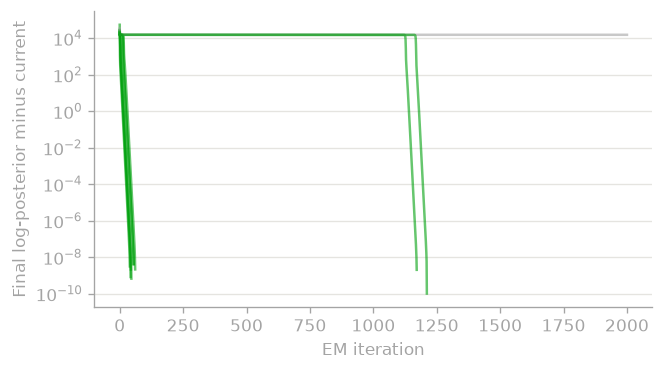

In [16]:
best = em_table["log-posterior"].max()
fig, ax = plt.subplots(figsize=(6, 3.2))
for history in histories:
    gap = np.maximum(best - history, 1e-10)
    # A start that ends far below the best log-posterior stopped at the local peak
    colour = BLUE if best - history[-1] < 1e-6 else GREY
    ax.semilogy(np.arange(len(history)), gap, color=colour, alpha=0.6, linewidth=1.5)
ax.set_xlabel("EM iteration")
ax.set_ylabel("Final log-posterior minus current")
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
fig.savefig("figures/layer3_em_convergence.pdf")
plt.show()

The fast starts follow straight lines, as in Layer 2: the error is divided by about the same factor at each step.

Starts 5 and 9 first stay on a flat stretch for about 1,100 steps, near the point where θ_E ≈ θ_B, then leave it and converge just as fast. So this point is not a real peak but a very flat region where EM moves very slowly: the grey start is still gaining about 0.0002 per step at step 2000 and would probably leave it later. This is why we use several starts and keep the best.

Lastly, we do importance sampling on Yambda in the same way we did for the simulated data earlier.

In [17]:
log_post = partial(ms.log_posterior, skips=train_skips, mask=train_mask, prior=PRIOR)
fit = po.importance_sampling_at_mode(log_post, po.to_vector(mode, ms.NAMES), N_DRAWS, rng, DF)
diagnostics = po.proposal_diagnostics(fit)
diagnostics.round(6)

draws outside the support (weight 0)        0.000000
draws                                   20000.000000
ESS                                     15915.822012
ESS share                                   0.795791
largest weight                              0.000087
dtype: float64

No draw breaks the constraint, the largest weight is tiny, and the ESS share is 0.80, the 5-dimensional benchmark of section 3.3. So the posterior is close to Normal on the log-odds scale, and the proposal, built from the EM mode and the Hessian, fits the posterior on the real data too.

## 6. Posterior summaries

We compute the posterior means, standard deviations and 95% intervals, as in Layer 2.

The switch probabilities are hard to read, so we add three quantities, computed for each draw:
- the mean length of an Engaged stretch, $1/q_{EB}$ tracks,
- the mean length of a Browsing stretch, $1/q_{BE}$ tracks,
- the long-run share of Browsing tracks, $q_{EB}/(q_{EB} + q_{BE})$.

In [18]:
summary = po.posterior_table(fit, ms.NAMES)
draw_params = po.to_params(fit["draws"], ms.NAMES)
# Each quantity is computed for each draw, so it has its own interval
derived = {
    "mean Engaged stretch (tracks)": 1 / draw_params["q_eb"],
    "mean Browsing stretch (tracks)": 1 / draw_params["q_be"],
    "long-run share of Browsing": draw_params["q_eb"] / (draw_params["q_eb"] + draw_params["q_be"]),
}
for name, values in derived.items():
    summary.loc[name] = pd.Series(po.weighted_summary(values, fit["weights"]))
summary.round(5)

,mean,sd,low,median,high
theta_e,0.06238,0.00211,0.05829,0.06236,0.06659
theta_b,0.85258,0.00326,0.84616,0.85255,0.85903
p0,0.56463,0.00946,0.54586,0.56461,0.58306
q_eb,0.03685,0.00149,0.03398,0.03683,0.03981
q_be,0.04537,0.00181,0.04190,0.04537,0.04897
mean Engaged stretch (tracks),27.17914,1.10037,25.12130,27.15207,29.42535
mean Browsing stretch (tracks),22.07669,0.88094,20.42273,22.04339,23.86642
long-run share of Browsing,0.44824,0.01096,0.42671,0.44825,0.46967


The two moods are further apart than the two types of Layer 2: θ_E ≈ 0.06 (0.11 in Layer 2) and θ_B ≈ 0.85 (0.76). Sessions that mix skips and plays are now explained by a switch, so each mood can be more extreme.

An Engaged stretch lasts about 27 tracks and a Browsing stretch about 22. This is longer than a session (10 to 20 tracks), so most sessions stay in one mood: switches are rare.

In the long run, 45% of tracks are Browsing, close to the 44% of sessions that start Browsing ($1 - p_0$). So the share of each mood barely changes along a session.

### 6.1 Monte Carlo error
As in Layer 2, we repeat the importance sampling with 10 seeds. The standard deviation of the posterior mean across seeds is the Monte Carlo error. It should be much smaller than the posterior standard deviation.

In [19]:
seed_means = po.means_over_seeds(log_post, po.to_vector(mode, ms.NAMES), N_DRAWS,
                                 range(1, 11), ms.NAMES, DF)
monte_carlo = pd.DataFrame({"posterior sd": summary.loc[ms.NAMES, "sd"],
                            "Monte Carlo error (sd over 10 seeds)": seed_means.std(ddof=1)})
monte_carlo

,posterior sd,Monte Carlo error (sd over 10 seeds)
theta_e,0.002106,0.000021
theta_b,0.003261,0.000027
p0,0.009457,0.000103
q_eb,0.001489,0.000017
q_be,0.001807,0.000016


The Monte Carlo error is about 90 to 120 times smaller than the posterior standard deviation for every parameter, as in Layer 2. So 20,000 draws are enough: the uncertainty comes from the data, not from the sampling.

These intervals assume the model is right. They ignore two things: many users have one session in each context, so sessions are not fully independent, and the model may still miss some structure in the data. So the real uncertainty is larger than shown here.

### 6.2 Correlations between parameters
We compute the correlations of the five parameters from the weighted draws.

In [20]:
correlation = po.weighted_correlation(fit, ms.NAMES)
correlation.round(3)

,theta_e,theta_b,p0,q_eb,q_be
theta_e,1.000,0.297,0.249,-0.288,-0.196
theta_b,0.297,1.000,0.266,0.187,0.293
p0,0.249,0.266,1.000,0.093,-0.051
q_eb,-0.288,0.187,0.093,1.000,0.390
q_be,-0.196,0.293,-0.051,0.390,1.000


All correlations are below 0.4, because on Yambda the two moods are far apart.

- θ_E is negatively correlated with both switch probabilities (−0.29 and −0.20). If Engaged tracks skip more, a skip in an Engaged stretch is less surprising, so fewer switches are needed.
- θ_B is positively correlated with both (0.19 and 0.29). If Browsing tracks skip more, a play in a Browsing stretch is more surprising, so it is more often explained by a switch.
- $q_{EB}$ and $q_{BE}$ are positively correlated (0.39). The data fix the long-run share of Browsing (about 45%), so when one switch probability goes up, the other goes up too.

### 6.3 Marginal posteriors
We plot the marginal posteriors as weighted histograms of the importance sampling draws. Each panel shows the central 99.9% of the posterior, so the few far draws of the Student-t (with almost no weight) do not squeeze the plot.

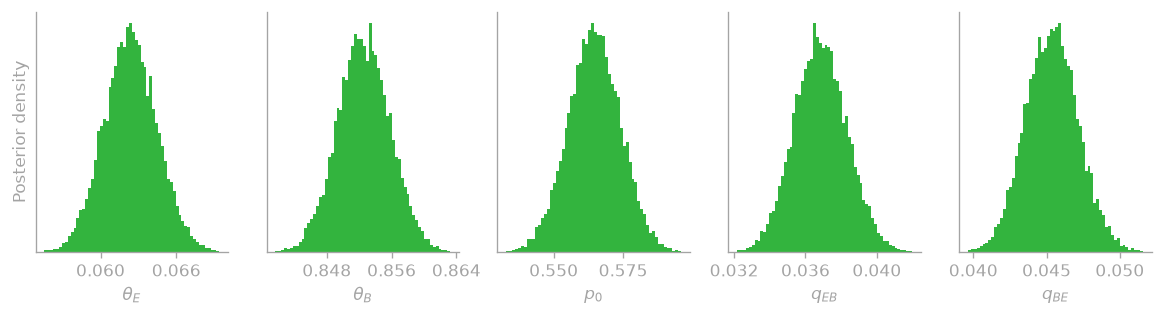

In [21]:
labels = {"theta_e": r"$\theta_E$", "theta_b": r"$\theta_B$", "p0": r"$p_0$",
          "q_eb": r"$q_{EB}$", "q_be": r"$q_{BE}$"}
fig, axes = plt.subplots(1, 5, figsize=(12, 2.6))
for ax, name in zip(axes, ms.NAMES):
    low, high = po.weighted_quantile(draw_params[name], fit["weights"], [0.0005, 0.9995])
    ax.hist(draw_params[name], bins=60, range=(low, high), weights=fit["weights"], density=True,
            histtype="stepfilled", color=BLUE, alpha=0.8)
    ax.set_xlabel(labels[name])
    ax.xaxis.set_major_locator(plt.MaxNLocator(3))
    ax.set_yticks([])
axes[0].set_ylabel("Posterior density")
fig.savefig("figures/layer3_posterior.pdf")
plt.show()

The five marginal posteriors are narrow and look like Normal curves, as expected from the high ESS.

### 6.4 How do moods change within a session?
In Layer 2 each session had one type. Here each track has its own mood, so we look at tracks and at switches.

First, for the rest of the notebook, we resample 1000 draws with probabilities equal to the weights, as in Layer 2. Then, for each draw, we compute with forward-backward:
- $P(\text{Browsing at } t \mid y_i)$ for each track,
- the expected number of switches in each session (the sum of the switch probabilities between neighbouring tracks).

We average both over the 1000 draws.

In [22]:
posterior_draws = po.resample(fit["draws"], fit["weights"], N_POSTERIOR, rng)
draws_params = [po.to_params(phi, ms.NAMES) for phi in posterior_draws]
print(f"{len(np.unique(posterior_draws, axis=0))} different draws out of {N_POSTERIOR}")

p_browsing = np.zeros(train_skips.shape)
switches = np.zeros(len(train_skips))
for p in draws_params:
    gamma, xi = ms.state_probabilities(p, train_skips, train_mask)
    p_browsing += gamma[..., 1] / N_POSTERIOR
    # Engaged then Browsing, plus Browsing then Engaged, summed over the pairs of the session
    switches += (xi[:, :, 0, 1] + xi[:, :, 1, 0]).sum(axis=1) / N_POSTERIOR

track_p = p_browsing[train_mask]
print(f"Tracks with P(Browsing) above 0.9: {(track_p > 0.9).mean():.3f}")
print(f"Tracks with P(Browsing) below 0.1: {(track_p < 0.1).mean():.3f}")
print(f"Tracks in between: {((track_p >= 0.1) & (track_p <= 0.9)).mean():.3f}")
print(f"Expected switches per session: {switches.mean():.2f}")
print(f"Sessions with less than 0.1 expected switch: {(switches < 0.1).mean():.3f}")
print(f"Sessions with at least 1 expected switch: {(switches >= 1).mean():.3f}")

973 different draws out of 1000


Tracks with P(Browsing) above 0.9: 0.386
Tracks with P(Browsing) below 0.1: 0.480
Tracks in between: 0.134
Expected switches per session: 0.59
Sessions with less than 0.1 expected switch: 0.391
Sessions with at least 1 expected switch: 0.270


973 of the 1000 resampled draws are different, so resampling kept enough variety.

Most tracks have a clear mood: 87% have P(Browsing) below 0.1 or above 0.9. The other 13% are uncertain, usually near a switch.

A session has on average 0.59 expected switches. 39% of sessions almost surely stay in one mood (less than 0.1 expected switch), and 27% have at least one expected switch. So about a quarter of the sessions mix the two moods, which Layer 2 could not represent.

We plot $P(\text{Browsing})$ along four training sessions. The dots show the real tracks: up for a skip, down for a play.

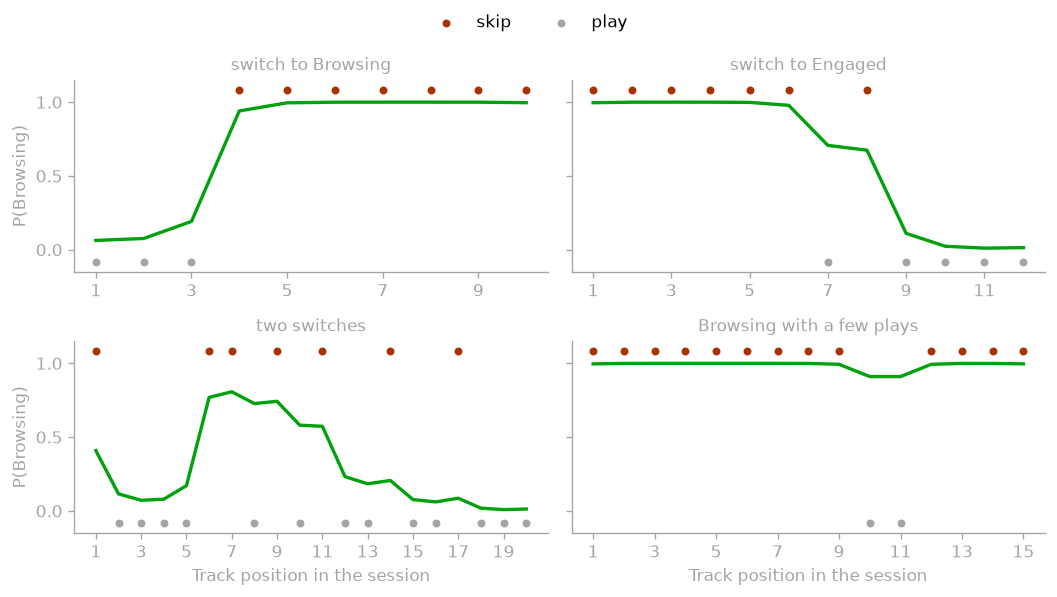

In [23]:
lengths = train_mask.sum(axis=1)
first_rate = p_browsing[:, 0]
last_rate = p_browsing[np.arange(len(lengths)), lengths - 1]
session_skip_rate = (train_skips * train_mask).sum(axis=1) / lengths

# One example of each kind: the first training session that matches the description
examples = {
    "switch to Browsing": (abs(switches - 1) < 0.2) & (first_rate < 0.1) & (last_rate > 0.9),
    "switch to Engaged": (abs(switches - 1) < 0.2) & (first_rate > 0.9) & (last_rate < 0.1),
    "two switches": abs(switches - 2) < 0.2,
    "Browsing with a few plays": (switches < 0.5) & (session_skip_rate > 0.6) & (session_skip_rate < 0.9),
}

fig, axes = plt.subplots(2, 2, figsize=(9, 5), sharey=True)
for ax, (title, matches) in zip(axes.ravel(), examples.items()):
    i = np.flatnonzero(matches)[0]
    positions = np.arange(1, lengths[i] + 1)
    skipped = train_skips[i, :lengths[i]] == 1
    ax.plot(positions, p_browsing[i, :lengths[i]], color=BLUE, linewidth=2)
    ax.scatter(positions[skipped], np.full(skipped.sum(), 1.08), color=ORANGE, s=14, label="skip")
    ax.scatter(positions[~skipped], np.full((~skipped).sum(), -0.08), color=GREY, s=14, label="play")
    ax.set_title(title, fontsize=10, color=GREY)
    ax.set_ylim(-0.15, 1.15)
    ax.set_xticks(positions[::2])
for ax in axes[1]:
    ax.set_xlabel("Track position in the session")
for ax in axes[:, 0]:
    ax.set_ylabel("P(Browsing)")
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig("figures/layer3_example_sessions.pdf")
plt.show()

- **Switch to Browsing**: three plays, then only skips. P(Browsing) jumps at track 4.
- **Switch to Engaged**: the opposite. The single skip at track 8 keeps some doubt (about 0.7) until the plays that follow.
- **Two switches**: Engaged, then a stretch with many skips (tracks 6 to 11), then Engaged again. The model is less sure in the middle (0.6 to 0.8), because this stretch mixes skips and plays.
- **Browsing with a few plays**: two plays in a row barely move P(Browsing) (0.91). A Browsing stretch lasts about 22 tracks, so two plays are more likely plays in a Browsing mood than two switches.

This is how Layer 3 can produce runs of skips: a mood holds for several tracks.

## 7. Posterior predictive checks
Can Layer 3 reproduce the real sessions? As in Layer 2, we simulate sessions with the training lengths for each of the 1000 posterior draws, and compute the same six statistics:

- the spread of skip rates between sessions,
- the gap after a skip,
- the longest run of skips,
- the gap after shuffling (20 shuffles): the part of the gap that comes from differences between sessions,
- the within-session gap: the gap after a skip minus the gap after shuffling, the part that comes from the order inside a session,
- the number of skip/play changes per session.

Layer 2 failed on the last two: it gave a within-session gap of 0 (real data 0.10) and too many changes (3.95 against 2.74). Layer 3 should do better, because a mood now holds for several tracks.

The real-data values use a fixed seed for the shuffles, so all layers report the same numbers.

In [24]:
observed = real_data_checks(train_skips, train_mask)
simulated = po.predictive_checks(ms.simulate, draws_params, train_lengths, rng, all_checks)
check_table = po.predictive_table(simulated, observed)
check_table.round(4)

,real data,simulated mean,simulated 2.5%,simulated 97.5%,share at least as large
spread of skip rates,0.3584,0.3320,0.3272,0.3368,0.0
gap after a skip,0.6134,0.5834,0.5722,0.5944,0.0
longest run of skips,4.7731,4.3680,4.1946,4.5251,0.0
gap after shuffling,0.5121,0.4058,0.3922,0.4183,0.0
within-session gap,0.1013,0.1776,0.1656,0.1905,1.0
skip/play changes,2.7415,2.9364,2.8502,3.0271,1.0


Layer 3 now produces runs of skips: the within-session gap is 0.18 and the skip/play changes are 2.94 (real data 0.10 and 2.74). But it overshoots the within-session gap.

Every statistic still rejects the model: none of the 1000 simulations reaches the real value (or, for the within-session gap and the changes, all are above it).

### 7.1 Layers 1, 2 and 3 side by side
We read the tables of Layers 1 and 2 from `results/layer1.json` and `results/layer2.json`. They use the same statistics, the same number of simulations and the same real-data values.

In [25]:
layer1_checks = pd.DataFrame(layer1["predictive_checks"]).T
assert np.allclose(layer1_checks["real data"], check_table["real data"])
assert np.allclose(layer2_checks["real data"], check_table["real data"])

pd.DataFrame({
    "real data": check_table["real data"],
    "Layer 1 mean": layer1_checks["simulated mean"],
    "Layer 2 mean": layer2_checks["simulated mean"],
    "Layer 3 mean": check_table["simulated mean"],
    "Layer 2 share ≥ real": layer2_checks["share at least as large"],
    "Layer 3 share ≥ real": check_table["share at least as large"],
}).round(4)

,real data,Layer 1 mean,Layer 2 mean,Layer 3 mean,Layer 2 share ≥ real,Layer 3 share ≥ real
spread of skip rates,0.3584,0.1294,0.3409,0.3320,0.0,0.0
gap after a skip,0.6134,-0.0001,0.4406,0.5834,0.0,0.0
longest run of skips,4.7731,2.7329,3.6023,4.3680,0.0,0.0
gap after shuffling,0.5121,-0.0000,0.4407,0.4058,0.0,0.0
within-session gap,0.1013,-0.0000,-0.0001,0.1776,0.0,1.0
skip/play changes,2.7415,7.0859,3.9486,2.9364,1.0,1.0


Layer 3 is closer to the real data than Layer 2 on the gap after a skip, the longest run of skips and the skip/play changes.

It is slightly worse on the spread of skip rates and on the gap after shuffling (0.41, against 0.44 for Layer 2 and 0.51 in the real data). So Layer 3 explains part of the differences between sessions by switches inside sessions. It explains too much this way: too much within-session gap, and too little gap after shuffling.

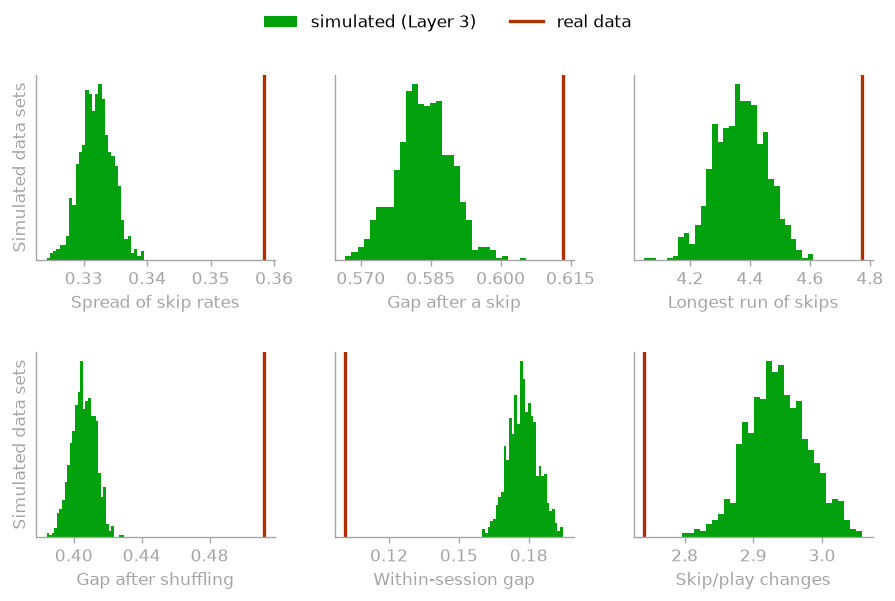

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(9, 5))
for ax, name in zip(axes.ravel(), simulated.columns):
    ax.hist(simulated[name], bins=30, color=BLUE, label="simulated (Layer 3)")
    ax.axvline(observed[name], color=ORANGE, linewidth=2, label="real data")
    ax.set_xlabel(name.capitalize())
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.set_yticks([])
axes[0, 0].set_ylabel("Simulated data sets")
axes[1, 0].set_ylabel("Simulated data sets")
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, frameon=False, loc="upper center", ncol=2)
fig.subplots_adjust(hspace=0.5, wspace=0.25)
fig.savefig("figures/layer3_predictive_checks.pdf")
plt.show()

In every panel the real value is still outside the simulated range. Layer 3 is the closest of the three layers, but every statistic rejects it.

### 7.2 Skip rate per session
In Layer 2, real sessions were more varied than two types allowed: more sessions with no skip, with only skips, and in the middle. We repeat the comparison with Layer 3, using 20 posterior draws as in Layer 2. The Layer 2 values are read from `results/layer2.json`.

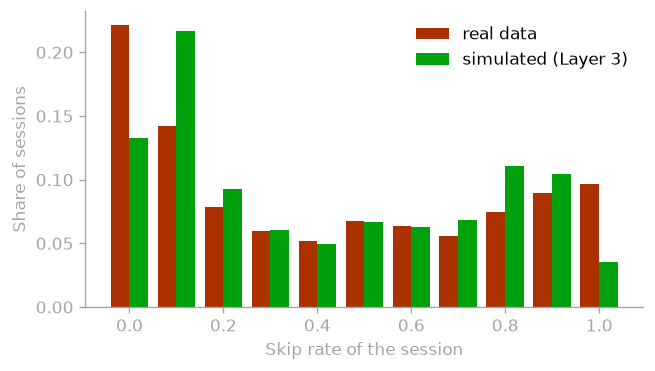

,real data,simulated (Layer 2),simulated (Layer 3)
no skip,0.221,0.099,0.132
at most 10% skips,0.337,0.316,0.304
30% to 70% skips,0.267,0.161,0.276
at least 90% skips,0.160,0.071,0.103
only skips,0.076,0.013,0.026


In [27]:
def session_rates(skips, mask):
    '''Return the skip rate of each session'''
    return (skips * mask).sum(axis=1) / mask.sum(axis=1)

real_rates = session_rates(train_skips, train_mask)
simulated_rates = np.concatenate([session_rates(*ms.simulate(p, train_lengths, rng)[:2])
                                  for p in draws_params[:20]])

# bins centred on 0, 0.1, ..., 1, so sessions with 0% or 100% skips have their own bin
edges = np.linspace(-0.05, 1.05, 12)
real_share = np.histogram(real_rates, bins=edges)[0] / len(real_rates)
simulated_share = np.histogram(simulated_rates, bins=edges)[0] / len(simulated_rates)
centres = np.linspace(0, 1, 11)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(centres - 0.02, real_share, width=0.04, color=ORANGE, label="real data")
ax.bar(centres + 0.02, simulated_share, width=0.04, color=BLUE, label="simulated (Layer 3)")
ax.set_xlabel("Skip rate of the session")
ax.set_ylabel("Share of sessions")
ax.legend(frameon=False)
fig.savefig("figures/layer3_skip_rate_per_session.pdf")
plt.show()

rate_groups = {
    "no skip": lambda r: r == 0,
    "at most 10% skips": lambda r: r <= 0.1,
    "30% to 70% skips": lambda r: (r >= 0.3) & (r <= 0.7),
    "at least 90% skips": lambda r: r >= 0.9,
    "only skips": lambda r: r == 1,
}
layer2_groups = pd.DataFrame(layer2["session_rate_groups"]).T
rate_table = pd.DataFrame({
    "real data": {name: rule(real_rates).mean() for name, rule in rate_groups.items()},
    "simulated (Layer 2)": layer2_groups["simulated (Layer 2)"],
    "simulated (Layer 3)": {name: rule(simulated_rates).mean() for name, rule in rate_groups.items()},
})
rate_table.round(3)

The middle of the distribution now matches: 28% of simulated sessions have 30% to 70% skips, against 27% in the real data (16% for Layer 2). Switches explain these mixed sessions.

The extremes are still too rare: 13% of sessions with no skip (22% real), and 3% with only skips (8% real). With about 15 tracks, a session with no skip must start Engaged (0.565), never switch ($0.963^{14} \approx 0.59$) and never skip ($0.94^{15} \approx 0.40$): $0.565 \times 0.59 \times 0.40 \approx 0.13$, as simulated.

This suggests a part of the data that switching cannot capture: some listeners skip much more, or much less, than the two moods allow. A model with differences between listeners would be the next step.

## 8. Sensitivity to the prior
Do our results depend on the prior? As in Layer 2, we repeat the fit (EM, then importance sampling) with Beta(1, 1) and Beta(5, 5) for all five parameters. For each prior, EM uses that prior raised by 1 (`log_odds_prior`), so the proposal is centred at the right log-odds mode.

One change from Layer 2: EM starts from the mode of section 5, not from a random point. A random start can get stuck in the flat region where θ_E ≈ θ_B (start 7 in section 5). The mode of section 5 is close to the mode under each prior, so EM only needs a few steps.

In [28]:
priors = {"Beta(1, 1)": (1, 1), "Beta(2, 2), main": (2, 2), "Beta(5, 5)": (5, 5)}
sensitivity = []
for label, (alpha, beta) in priors.items():
    prior = {name: (alpha, beta) for name in ms.NAMES}
    prior_mode, _ = ms.em(mode, train_skips, train_mask, prior=po.log_odds_prior(prior))
    prior_log_post = partial(ms.log_posterior, skips=train_skips, mask=train_mask, prior=prior)
    prior_fit = po.importance_sampling_at_mode(prior_log_post, po.to_vector(prior_mode, ms.NAMES),
                                               N_DRAWS, rng, DF)
    table = po.posterior_table(prior_fit, ms.NAMES)[["mean", "low", "high"]]
    table.insert(0, "prior", label)
    table["ESS share"] = prior_fit["ess_share"]
    sensitivity.append(table)
sensitivity = pd.concat(sensitivity)
sensitivity.round(5)

,prior,mean,low,high,ESS share
theta_e,"Beta(1, 1)",0.06239,0.05820,0.06654,0.79997
theta_b,"Beta(1, 1)",0.85257,0.84621,0.85891,0.79997
p0,"Beta(1, 1)",0.56472,0.54617,0.58296,0.79997
q_eb,"Beta(1, 1)",0.03678,0.03393,0.03972,0.79997
q_be,"Beta(1, 1)",0.04530,0.04179,0.04890,0.79997
theta_e,"Beta(2, 2), main",0.06235,0.05826,0.06656,0.80163
theta_b,"Beta(2, 2), main",0.85259,0.84633,0.85897,0.80163
p0,"Beta(2, 2), main",0.56461,0.54618,0.58327,0.80163
q_eb,"Beta(2, 2), main",0.03687,0.03400,0.03983,0.80163
q_be,"Beta(2, 2), main",0.04539,0.04189,0.04898,0.80163


The three priors give the same posterior means and intervals to the 3rd decimal, and the ESS stays at about 80%.

The largest change is for $q_{BE}$: 0.0453 to 0.0456, much smaller than its posterior standard deviation (0.0018). Beta(5, 5) pulls the switch probabilities towards 0.5, yet they barely move. So the switches come from the data, not from the prior.

As in Layer 2, the data (about 67,000 tracks) carry much more information than a prior worth a few observations.

## 9. Additional analysis: predicting new listeners
As in Layer 2, we check how well the model predicts the tracks of listeners it has never seen. This is not a check of the model (sections 3 and 7 are), just an extra question.

Each test track gets its probability of a skip given the earlier tracks of its session, and we average the logs of the probabilities given to what really happened. Higher is better.

Layer 2 updated the type of the whole session after each track. Layer 3 updates the mood of the current track with the forward algorithm, and lets it switch before the next track:

$$P(\text{skip at } t \mid y_{<t}) = P(E \text{ at } t \mid y_{<t})\,\theta_E + P(B \text{ at } t \mid y_{<t})\,\theta_B$$

where $P(E \text{ at } t \mid y_{<t}) = P(E \text{ at } t-1 \mid y_{<t})(1 - q_{EB}) + P(B \text{ at } t-1 \mid y_{<t})\,q_{BE}$. At the first track, $P(E) = p_0$. We average over the 1000 posterior draws, and also compute the score at the posterior mean as a check.

In [29]:
predictive = sum(ms.skip_probabilities(p, test_skips, test_mask)
                 for p in draws_params) / N_POSTERIOR
score = average_log_score(predictive, test_skips, test_mask)

posterior_mean = {name: summary.loc[name, "mean"] for name in ms.NAMES}
score_at_mean = average_log_score(ms.skip_probabilities(posterior_mean, test_skips, test_mask),
                                  test_skips, test_mask)

print(f"Layer 3, averaged over the posterior: {score:.4f}")
print(f"Layer 3, at the posterior mean:       {score_at_mean:.4f}")
print(f"Layer 2, averaged over the posterior: {layer2['score_posterior_predictive']:.4f}")
print(f"Layer 1, one skip rate:               {layer1['score_one_rate']:.4f}")
print(f"Fair coin:                            {np.log(0.5):.4f}")

Layer 3, averaged over the posterior: -0.4462
Layer 3, at the posterior mean:       -0.4462
Layer 2, averaged over the posterior: -0.4788
Layer 1, one skip rate:               -0.6782
Fair coin:                            -0.6931


Layer 3 predicts new listeners better than Layer 2: −0.446 against −0.479. The gain is smaller than from Layer 1 to Layer 2 (−0.678 to −0.479): knowing the mood of the session matters most, and switches add a smaller correction.

Averaging over the posterior or using the posterior mean gives the same score, because the posterior is very narrow.

## 10. Save the results
We save every number in `results/layer3.json`, in the same format as `results/layer2.json`. The predictive-check table has the same six rows and columns as in Layers 1 and 2, and `em_mode` is the EM mode of section 5, written as probabilities.

In [30]:
def table_to_dict(table):
    '''Turn a DataFrame into a dict that json can write'''
    return json.loads(table.to_json(orient="index"))

results = {
    "em_mode": {name: float(value) for name, value in mode.items()},
    "posterior": table_to_dict(summary),
    "correlation": table_to_dict(correlation),
    "monte_carlo_error": {"seeds": 10, **table_to_dict(monte_carlo)},
    "importance_sampling": {"draws": N_DRAWS, "df": DF,
                            **table_to_dict(diagnostics.to_frame("value"))},
    "proposal_comparison": json.loads(comparison.to_json(orient="records")),
    "simulated": {"true": TRUE,
                  "posterior": table_to_dict(po.posterior_table(sim_fit, ms.NAMES, TRUE))},
    "share_tracks_browsing_above_0.9": float((track_p > 0.9).mean()),
    "expected_switches_per_session": float(switches.mean()),
    "observed_checks": {name: float(value) for name, value in observed.items()},
    "predictive_checks": table_to_dict(check_table),
    "session_rate_groups": table_to_dict(rate_table),
    "score_posterior_predictive": float(score),
    "score_posterior_mean": float(score_at_mean),
    "prior_sensitivity": json.loads(sensitivity.reset_index(names="parameter")
                                    .to_json(orient="records")),
}
with open("results/layer3.json", "w") as file:
    json.dump(results, file, indent=2)
print(list(results))

['em_mode', 'posterior', 'correlation', 'monte_carlo_error', 'importance_sampling', 'proposal_comparison', 'simulated', 'share_tracks_browsing_above_0.9', 'expected_switches_per_session', 'observed_checks', 'predictive_checks', 'session_rate_groups', 'score_posterior_predictive', 'score_posterior_mean', 'prior_sensitivity']


## 11. The three layers side by side
We gather the main numbers of the three layers. A statistic "rejects" a layer when the real value is outside the central 95% of its simulations (share at least as large below 0.025 or above 0.975).

In [31]:
layer_checks = {"Layer 1": layer1_checks, "Layer 2": layer2_checks, "Layer 3": check_table}
final = pd.DataFrame({
    "parameters": [1, 3, 5],
    "within-session gap (real 0.101)": [table.loc["within-session gap", "simulated mean"]
                                        for table in layer_checks.values()],
    "skip/play changes (real 2.742)": [table.loc["skip/play changes", "simulated mean"]
                                       for table in layer_checks.values()],
    "statistics that reject the layer (out of 6)": [
        int(((table["share at least as large"] < 0.025)
             | (table["share at least as large"] > 0.975)).sum())
        for table in layer_checks.values()],
    "test score (higher is better)": [layer1["score_one_rate"],
                                      layer2["score_posterior_predictive"], score],
}, index=list(layer_checks))
final.round(3)

,parameters,within-session gap (real 0.101),skip/play changes (real 2.742),statistics that reject the layer (out of 6),test score (higher is better)
Layer 1,1,-0.000,7.086,6,-0.678
Layer 2,3,-0.000,3.949,6,-0.479
Layer 3,5,0.178,2.936,6,-0.446


Each layer improves on the one before. Layer 2 adds differences between sessions, and Layer 3 adds runs of skips inside a session. Layer 3 has the best test score and the closest skip/play changes.

But every layer is still rejected by all six statistics. Layer 3 gives too much within-session gap (0.18 against 0.10) and too few sessions with no skip or only skips (section 7.2). This points to differences between listeners, which none of the three layers models.

So the moods are a useful summary, not a full description of the data: Engaged and Browsing stretches exist, and they explain a large part of the skips. The remaining gaps are where a next model would start.